# Pizza or Not Pizza? Full Project Notebook

**DATA 4380 Data Problems | The University of Texas at Arlington | Dr. Masoud Rostami, Instructor**

This project develops and evaluates image classification models to distinguish pizza images from images of other foods using the Pizza or Not Pizza dataset. The notebook follows a complete data science workflow, from exploratory data analysis and preprocessing to model development, evaluation, and interpretation.

The dataset contains 1,966 images, evenly split between the `pizza` and `not_pizza` classes. Images are resized to a consistent input size and divided into stratified training, validation, and test sets. Multiple modeling approaches are investigated, beginning with simple baselines and progressing to transfer learning with pretrained convolutional neural networks.

| Step | Where |
|---|---|
| Data understanding and exploratory data analysis | Section 2 |
| Data preprocessing, image resizing, and dataset splitting | Section 1 |
| Baseline models: majority-class prediction and a small CNN trained from scratch | Section 3 |
| MobileNetV2 transfer learning | Section 4 |
| Augmentation comparison | Section 5 |
| Comparison of MobileNetV2, EfficientNetB0, and ResNet50 | Section 6 |
| Hyperparameter tuning using the validation set | Section 7 |
| Fine-tuning the selected pretrained network | Section 8 |
| Final model evaluation on the held-out test set | Section 9 |
| Model interpretation, Grad-CAM visualizations, and error analysis | Section 10 |

Model selection and hyperparameter decisions are based on validation-set performance. The held-out test set is reserved for final evaluation to provide an independent assessment of the selected model's performance. Results and evaluation metrics are saved to `outputs/tf/results.json`, and generated figures are saved to `outputs/tf/figures/`.

## 1. Setup, loading the photos and splitting the data

In [8]:
from pathlib import Path #imports

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

import os, json, time, hashlib, itertools
import pandas as pd
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

These are all functions needed for the entire process.

In [9]:
def find_images(folder): #finding image files in a folder
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder}")

    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

    return sorted(
        str(path) for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in extensions
    )


def load_image(path, label): #reading, resizing, and preparing images
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)

    label = tf.reshape(tf.cast(label, tf.float32), [1])
    return image, label


def make_dataset(paths, labels, training=False): #creating an efficient image dataset
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(len(paths), seed=SEED) #shuffling training images

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def savefig(name): #saving and displaying plots
    plt.savefig(FIG / f"{name}.png")
    plt.show()


def scores(y_true, prob, threshold=0.5): #evaluating classification performance
    pred = (np.asarray(prob) >= threshold).astype(int)

    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob)
    }


def record(name, model): #storing validation and test predictions
    val_probs[name] = model.predict(val_ds, verbose=0).ravel()
    test_probs[name] = model.predict(test_ds, verbose=0).ravel()
    return scores(y_val, val_probs[name])


def fit(model, lr=0.001, epochs=15, patience=3, ds=None): #training with early stopping
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=patience,
        restore_best_weights=True
    )

    start = time.time()
    history = model.fit(
        train_ds if ds is None else ds,
        validation_data=val_ds,
        epochs=1 if QUICK else epochs,
        callbacks=[early_stop],
        verbose=0
    )

    history.history["seconds"] = time.time() - start
    return history


def plot_history(history, title, name): #comparing training and validation performance
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = range(1, len(history.history["loss"]) + 1)

    axes[0].plot(epochs, history.history["accuracy"], label="Training")
    axes[0].plot(epochs, history.history["val_accuracy"], label="Validation")
    axes[0].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[0].legend()

    axes[1].plot(epochs, history.history["loss"], label="Training")
    axes[1].plot(epochs, history.history["val_loss"], label="Validation")
    axes[1].set(title="Loss", xlabel="Epoch", ylabel="Binary cross-entropy")
    axes[1].legend()

    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    savefig(name)


def gap(history): #checking the training-validation accuracy gap
    best = int(np.argmin(history.history["val_loss"]))
    return float(
        history.history["accuracy"][best]
        - history.history["val_accuracy"][best]
    )


def build_transfer(backbone="MobileNetV2", augment=True, dropout=0.2):
    #building a transfer-learning model with a frozen pretrained backbone
    app, preprocess = BACKBONES[backbone]
    base = app(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False

    inputs = tf.keras.Input(shape=(224, 224, 3))

    #adding augmentation and extracting visual features
    x = inputs
    if augment:
        x = tf.keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05)
        ])(x)

    x = preprocess(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inputs, outputs)

    INFO[id(model)] = {"base": base, "backbone": backbone}
    return model

def gradcam(m, img):
    """Generate a Grad-CAM heatmap from a pretrained model's feature map."""
    pool = next(l for l in m.layers if isinstance(l, layers.GlobalAveragePooling2D))
    drop = next(l for l in m.layers if isinstance(l, layers.Dropout))
    dense = next(l for l in m.layers if isinstance(l, layers.Dense))
    prep = BACKBONES[INFO[id(m)]["backbone"]][1]
    x = prep(tf.cast(img[None], tf.float32))

    with tf.GradientTape() as tape:
        fmap = INFO[id(m)]["base"](x, training=False)
        tape.watch(fmap)
        out = dense(drop(pool(fmap), training=False))

    g = tape.gradient(out, fmap)
    w = tf.reduce_mean(g, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * fmap, axis=-1))[0].numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8) #normalizing the heatmap

    return cam, float(out.numpy().ravel()[0])


def gradcam_grid(idx, title, name):
    fig, axes = plt.subplots(2, len(idx), figsize=(2.6 * len(idx), 5.8), squeeze=False)

    for c, i in enumerate(idx):
        img = test_imgs[i]
        cam, prob = gradcam(final_model, img)
        cam = np.array(Image.fromarray(np.uint8(cam * 255)).resize((224, 224))) / 255 #resizing the heatmap to match the image

        axes[0, c].imshow(img.astype("uint8"))
        axes[0, c].axis("off")
        axes[0, c].set_title(f"Actually {CLASS_NAMES[y_test[i]].replace('_', ' ')}\nP(pizza) = {prob:.2f}", fontsize=10)

        axes[1, c].imshow(img.astype("uint8"))
        axes[1, c].imshow(cam, cmap="jet", alpha=0.45)
        axes[1, c].axis("off")

    fig.suptitle(title, fontweight="bold")
    savefig(name)

This cell loads the image paths and sets the project settings.

In [10]:
PIZZA_DIR = Path("C:\\DATA 4380\\Tabular Project\\pizza_not_pizza\\pizza") #leads to folders with pizza and non-pizza images (path updated for this project folder, change path name as needed)
NOT_PIZZA_DIR = Path("C:\\DATA 4380\\Tabular Project\\pizza_not_pizza\\not_pizza")

CLASS_NAMES = ["not_pizza", "pizza"] #initializing project settings
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)

pizza_files = find_images(PIZZA_DIR) #loading the sets of file paths
not_pizza_files = find_images(NOT_PIZZA_DIR)

if not not_pizza_files or not pizza_files:
    raise ValueError("Both folders must contain supported image files.")

file_paths = not_pizza_files + pizza_files #assigning labels to images
labels = [0] * len(not_pizza_files) + [1] * len(pizza_files)

print("Not pizza images:", len(not_pizza_files))
print("Pizza images:", len(pizza_files))

Not pizza images: 983
Pizza images: 983


A stratified split keeps 50% pizza in each part. 70% of the photos are for training, 15% for validation and 15% for testing.

In [11]:
train_paths, remaining_paths, train_labels, remaining_labels = ( #training set split
    train_test_split(
        file_paths,
        labels,
        test_size=0.30,
        stratify=labels,
        random_state=SEED
    )
)

val_paths, test_paths, val_labels, test_labels = train_test_split( #validation and testing set split
    remaining_paths,
    remaining_labels,
    test_size=0.50,
    stratify=remaining_labels,
    random_state=SEED
)

train_ds = make_dataset(train_paths, train_labels, training=True) #creating datasets for training, validation, and testing
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

Training images: 1376
Validation images: 295
Testing images: 295


These cells set up the output folders, a scoring function that reports accuracy, precision, recall, F1 and
ROC-AUC, a training helper with the same early stopping as the original, and a builder that recreates the original
MobileNetV2 design for any pretrained network.

In [12]:
OUT = Path("outputs/tf")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True) #creating folders for output figures

R = {} #storing results and metrics for the presentation

COLORS = { #setting consistent colors and formatting for plots
    "pizza": "#D1495B",
    "not_pizza": "#00798C",
    "neutral": "#5C6B73",
    "highlight": "#EDAE49",
    "baseline": "#9AA5AB"
}

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False
})

y_val = np.array(val_labels) #converting labels to NumPy arrays and initializing model tracking
y_test = np.array(test_labels)

val_probs, test_probs, histories = {}, {}, {}
models_by_name = {}
INFO = {}

QUICK = os.environ.get("PIZZA_QUICK") == "1" #using one epoch per model for quick testing

BACKBONES = { #selecting pretrained models and their matching preprocessing functions
    "MobileNetV2": (
        tf.keras.applications.MobileNetV2,
        tf.keras.applications.mobilenet_v2.preprocess_input
    ),
    "EfficientNetB0": (
        tf.keras.applications.EfficientNetB0,
        tf.keras.applications.efficientnet.preprocess_input
    ),
    "ResNet50": (
        tf.keras.applications.ResNet50,
        tf.keras.applications.resnet50.preprocess_input
    )
}

## 2. Data understanding and EDA
We check for duplicates and unreadable files, look at the class balance in every split, the image sizes,
the average colour of each class, and a sample of photos.

In [13]:
info = []

for p, lab in zip(file_paths, labels): #collecting image properties and checking for exact duplicates
    with Image.open(p) as im:
        rgb = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32) / 255

        info.append({
            "path": p,
            "label": lab,
            "class": CLASS_NAMES[lab],
            "width": im.width,
            "height": im.height,
            "mode": im.mode,
            "md5": hashlib.md5(open(p, "rb").read()).hexdigest(),
            **dict(zip("RGB", rgb.reshape(-1, 3).mean(0)))
        })

meta = pd.DataFrame(info)

split_of = { #identifying which dataset split each image belongs to
    **{p: "train" for p in train_paths},
    **{p: "val" for p in val_paths},
    **{p: "test" for p in test_paths}
}
meta["split"] = meta["path"].map(split_of)

R["eda"] = { #summarizing dataset size, quality, image properties, and color information
    "n_images": len(meta),
    "class_counts": meta["class"].value_counts().to_dict(),
    "exact_duplicates": int(meta.duplicated("md5").sum()),
    "unreadable_files": 0,
    "modes": meta["mode"].value_counts().to_dict(),
    "n_unique_sizes": int(meta.groupby(["width", "height"]).ngroups),
    "pct_512x512": round(
        float(((meta.width == 512) & (meta.height == 512)).mean() * 100), 1
    ),
    "split_counts": meta.groupby(["split", "class"]).size().unstack().to_dict("index"),
    "mean_rgb": meta.groupby("class")[["R", "G", "B"]].mean().round(3).to_dict("index")
}

print(json.dumps(R["eda"], indent=1))

{
 "n_images": 1966,
 "class_counts": {
  "not_pizza": 983,
  "pizza": 983
 },
 "exact_duplicates": 0,
 "unreadable_files": 0,
 "modes": {
  "RGB": 1966
 },
 "n_unique_sizes": 74,
 "pct_512x512": 55.1,
 "split_counts": {
  "test": {
   "not_pizza": 148,
   "pizza": 147
  },
  "train": {
   "not_pizza": 688,
   "pizza": 688
  },
  "val": {
   "not_pizza": 147,
   "pizza": 148
  }
 },
 "mean_rgb": {
  "not_pizza": {
   "R": 0.5450000166893005,
   "G": 0.4440000057220459,
   "B": 0.34700000286102295
  },
  "pizza": {
   "R": 0.5630000233650208,
   "G": 0.4090000092983246,
   "B": 0.30000001192092896
  }
 }
}


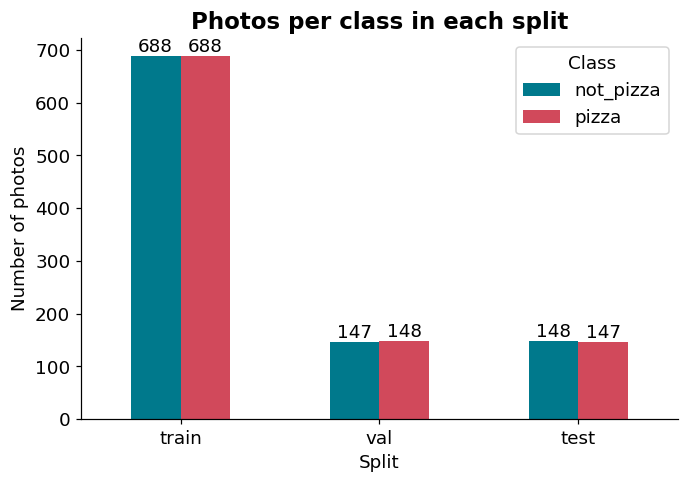

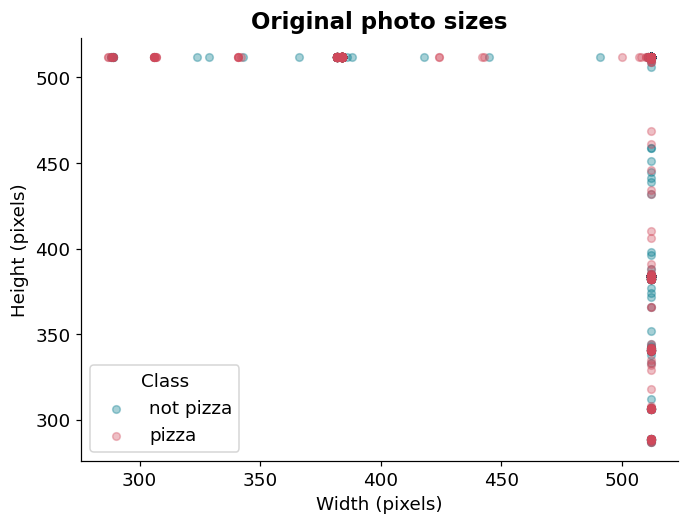

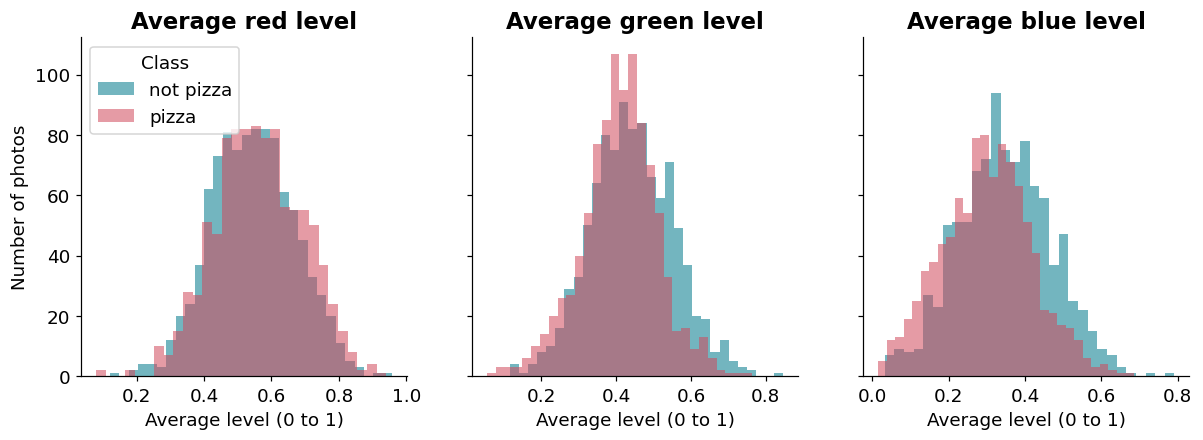

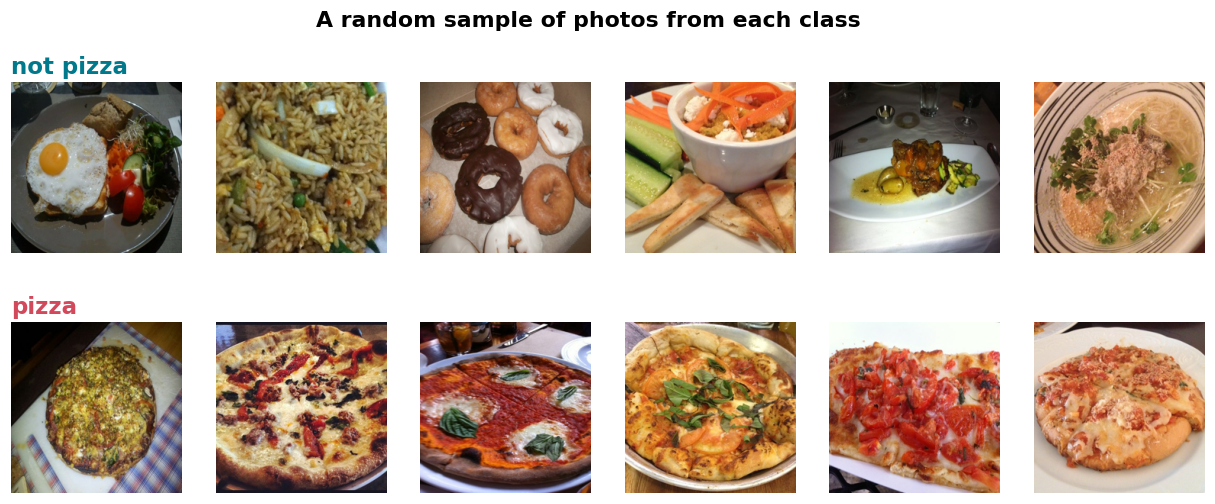

In [14]:
ct = meta.groupby(["split", "class"]).size().unstack().loc[["train", "val", "test"]] #comparing class counts across the dataset splits

ax = ct.plot(
    kind="bar",
    color=[COLORS["not_pizza"], COLORS["pizza"]],
    figsize=(7, 4.5),
    rot=0
)
for c in ax.containers:
    ax.bar_label(c)

ax.set(title="Photos per class in each split", xlabel="Split", ylabel="Number of photos")
ax.legend(title="Class")
savefig("eda_class_balance")

fig, ax = plt.subplots(figsize=(7, 5)) #comparing the original image dimensions

for cls in CLASS_NAMES:
    d = meta[meta["class"] == cls]
    ax.scatter(
        d.width, d.height, alpha=0.35, s=25,
        label=cls.replace("_", " "), color=COLORS[cls]
    )

ax.set(title="Original photo sizes", xlabel="Width (pixels)", ylabel="Height (pixels)")
ax.legend(title="Class")
savefig("eda_image_sizes")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True) #comparing average RGB color levels between classes

for ax, ch, name in zip(axes, "RGB", ["red", "green", "blue"]):
    for cls in CLASS_NAMES:
        ax.hist(
            meta.loc[meta["class"] == cls, ch],
            bins=30, alpha=0.55,
            color=COLORS[cls],
            label=cls.replace("_", " ")
        )
    ax.set(title=f"Average {name} level", xlabel="Average level (0 to 1)")

axes[0].set_ylabel("Number of photos")
axes[0].legend(title="Class")
savefig("eda_color_hist")

fig, axes = plt.subplots(2, 6, figsize=(14, 5.2)) #displaying a reproducible random sample of images from each class
rng = np.random.RandomState(SEED)

for r_, cls in enumerate(CLASS_NAMES):
    samples = meta[meta["class"] == cls].sample(6, random_state=rng)

    for ax, p in zip(axes[r_], samples["path"]):
        with Image.open(p) as im:
            ax.imshow(im.convert("RGB").resize((224, 224)))
        ax.axis("off")

    axes[r_, 0].set_title(cls.replace("_", " "), loc="left", color=COLORS[cls])

fig.suptitle("A random sample of photos from each class", fontweight="bold")
savefig("eda_samples")


## 3. Baselines
Two baselines give every later result something to be compared against.
* **Majority guess.** It always predicts the most common class in the training set. With balanced classes this gives 50% accuracy.
* **Small CNN from scratch.** Three convolution blocks with no pretrained knowledge and no augmentation. It uses only the minimum preprocessing (resize and scale).

In [15]:
majority = int(np.bincount(train_labels).argmax()) #creating a baseline that always predicts the majority training class

val_probs["Majority guess (baseline)"] = np.full(len(y_val), float(majority))
test_probs["Majority guess (baseline)"] = np.full(len(y_test), float(majority))

print("Majority class in training:", CLASS_NAMES[majority])
print("Validation scores:", scores(y_val, val_probs["Majority guess (baseline)"]))

Majority class in training: not_pizza
Validation scores: {'Accuracy': 0.49830508474576274, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.5}


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Validation: {'Accuracy': 0.823728813559322, 'Precision': 0.875, 'Recall': 0.7567567567567568, 'F1': 0.8115942028985508, 'ROC-AUC': 0.8866979224122081} | epochs: 30 | gap: -0.022


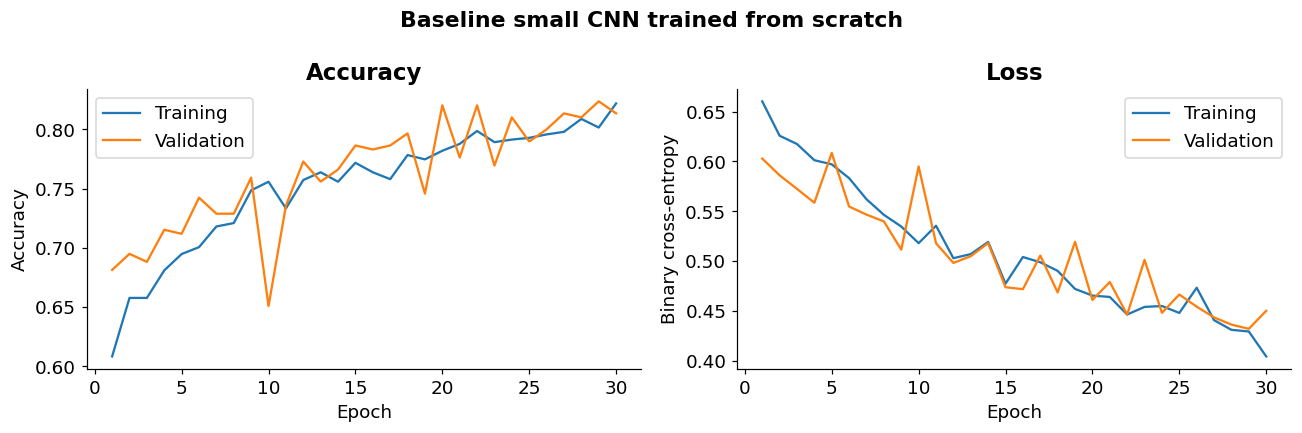

In [16]:
tf.keras.utils.set_random_seed(SEED) #setting the random seed for reproducibility

small_cnn = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    layers.Resizing(128, 128), layers.Rescaling(1 / 255.0), #resizing and normalizing images
    layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(), layers.Dropout(0.3), layers.Dense(1, activation="sigmoid"), #classification layers
], name="small_cnn")

R["small_cnn_params"] = int(small_cnn.count_params()) #counting model parameters
histories["Small CNN (baseline)"] = h = fit(small_cnn, lr=0.001, epochs=30, patience=5)
print("Validation:", record("Small CNN (baseline)", small_cnn), "| epochs:", len(h.history["loss"]), "| gap:", round(gap(h), 3))
plot_history(h, "Baseline small CNN trained from scratch", "curves_small_cnn")

## 4. MobileNetV2 Training and Initial Evaluation

The MobileNetV2 model is trained using transfer learning, with its pretrained convolutional base frozen and a new classification head trained on the pizza dataset. Training history and model metadata are retained for later comparison and interpretation.

The model's initial test-set performance is evaluated using accuracy, loss, precision, recall, F1-score, and a confusion matrix. These results provide an initial reference point for the subsequent experiments. The full workflow later compares all candidate models using the same held-out test set, while model selection and tuning are based on validation-set performance.

In [17]:
augmentation = tf.keras.Sequential([ #adding variety to training images
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05)
])

base_model = tf.keras.applications.MobileNetV2( #loading MobileNetV2 to extract visual features from images
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False #freezing the base model so that its weights are not updated during training

inputs = tf.keras.Input(shape=(224, 224, 3))

x = augmentation(inputs) #connecting preprocessing layers to the input layer and 
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(1, activation="sigmoid")(x) #creating binary out layer

model = tf.keras.Model(inputs, outputs) #assembling and compiling model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Training with early stopping, then the accuracy and loss curves.

Epoch 1/15


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


43/43 ━━━━━━━━━━━━━━━━━━━━ 48s 954ms/step - accuracy: 0.7536 - loss: 0.5113 - val_accuracy: 0.9085 - val_loss: 0.2618
Epoch 2/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 34s 798ms/step - accuracy: 0.9273 - loss: 0.2297 - val_accuracy: 0.9153 - val_loss: 0.2110
Epoch 3/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 33s 779ms/step - accuracy: 0.9382 - loss: 0.1869 - val_accuracy: 0.9186 - val_loss: 0.1932
Epoch 4/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 35s 817ms/step - accuracy: 0.9433 - loss: 0.1503 - val_accuracy: 0.9220 - val_loss: 0.1872
Epoch 5/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 35s 826ms/step - accuracy: 0.9491 - loss: 0.1405 - val_accuracy: 0.9220 - val_loss: 0.1786
Epoch 6/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 35s 806ms/step - accuracy: 0.9477 - loss: 0.1373 - val_accuracy: 0.9322 - val_loss: 0.1756
Epoch 7/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 34s 784ms/step - accuracy: 0.9593 - loss: 0.1246 - val_accuracy: 0.9254 - val_loss: 0.1760
Epoch 8/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 34s 788ms/step - accuracy: 0.9513 - loss: 0.1267 - val_accuracy: 0.928

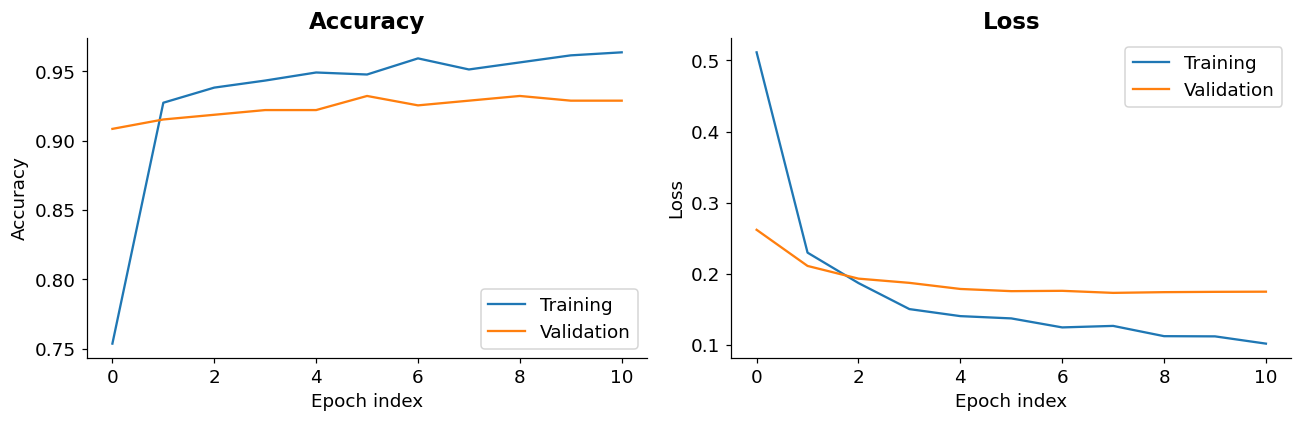

In [18]:
early_stop = tf.keras.callbacks.EarlyStopping( #early stopping to prevent overfitting
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit( #model training
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4)) #plotting training and validation accuracy and loss over epochs

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch index")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch index")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

Test loss: 0.1429
Test accuracy: 94.24%

Classification report:
              precision    recall  f1-score   support

   not_pizza       0.95      0.93      0.94       148
       pizza       0.93      0.95      0.94       147

    accuracy                           0.94       295
   macro avg       0.94      0.94      0.94       295
weighted avg       0.94      0.94      0.94       295



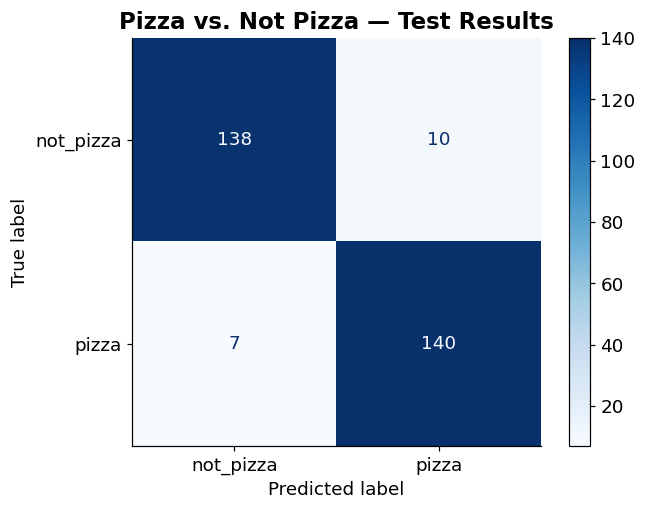

In [19]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0) #evaluates model performance on the test dataset

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

y_true = np.concatenate([ #collecting labels and predictions for classification report and confusion matrix
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

probabilities = model.predict(test_ds, verbose=0).ravel() #generating probabilities for each image being pizza
y_pred = (probabilities >= 0.5).astype(int)

print("\nClassification report:") #displaying classification report with precision, recall, and F1-score for each class
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions( #displaying confusion matrix to visualize model performance
    y_true,
    y_pred,
    labels=[0, 1],
    display_labels=CLASS_NAMES,
    cmap="Blues"
)

plt.title("Pizza vs. Not Pizza — Test Results")
plt.tight_layout()
plt.show()

Validation: {'Accuracy': 0.9288135593220339, 'Precision': 0.9261744966442953, 'Recall': 0.9324324324324325, 'F1': 0.9292929292929293, 'ROC-AUC': 0.9833609119323405} | epochs: 11 | gap: 0.022


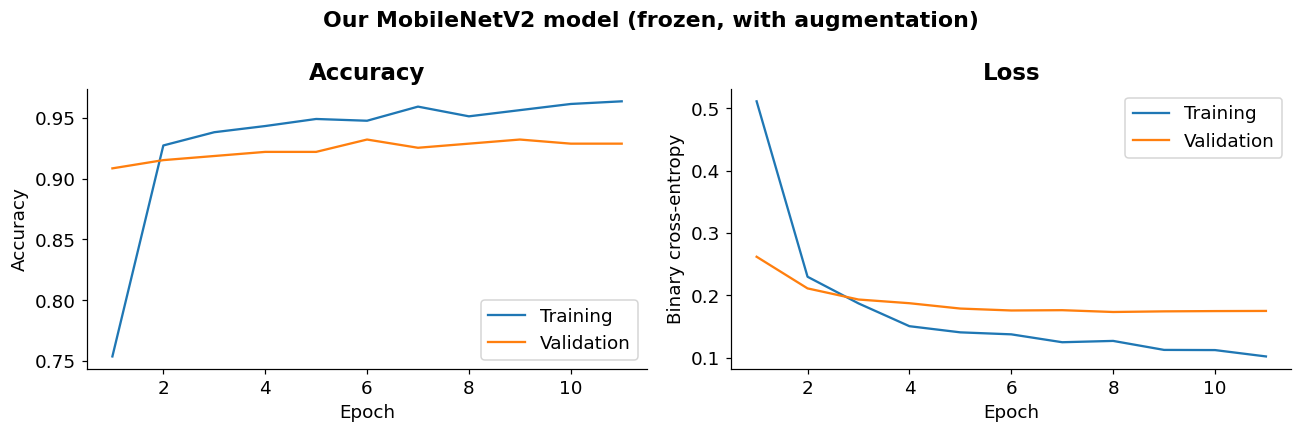

In [20]:
histories["MobileNetV2 (frozen)"] = history #storing the original model's training history
history.history["seconds"] = float("nan") #marking training time as unavailable

INFO[id(model)] = {"base": base_model, "backbone": "MobileNetV2"} #saving model metadata for Grad-CAM
models_by_name["MobileNetV2 (frozen)"] = model #storing the trained model

print("Validation:", record("MobileNetV2 (frozen)", model), "| epochs:", len(history.history["loss"]), "| gap:", round(gap(history), 3))
plot_history(history, "Our MobileNetV2 model (frozen, with augmentation)", "curves_mobilenet")

## 5. Additional preprocessing. Does augmentation help?
The original model flips and slightly rotates training photos. To measure what that adds, we train the same
MobileNetV2 without augmentation and compare the validation scores. Everything else stays the same.

In [21]:
tf.keras.utils.set_random_seed(SEED) #setting the random seed for reproducibility
m_noaug = build_transfer("MobileNetV2", augment=False) #building MobileNetV2 without data augmentation

histories["MobileNetV2, no augmentation"] = h = fit(m_noaug) #training and storing the training history
models_by_name["MobileNetV2, no augmentation"] = m_noaug #storing the trained model

print("Validation without augmentation:", record("MobileNetV2, no augmentation", m_noaug), "| gap:", round(gap(h), 3))

C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Validation without augmentation: {'Accuracy': 0.9355932203389831, 'Precision': 0.9387755102040817, 'Recall': 0.9324324324324325, 'F1': 0.9355932203389831, 'ROC-AUC': 0.9838205552491266} | gap: 0.026


## 6. Model comparison. Other pretrained networks with the same design
We swap the MobileNetV2 base for two other well-known pretrained networks, using the same augmentation, frozen
base, dropout, final layer and training settings. EfficientNetB0 is known for being very accurate for its size, and
ResNet50 is a larger, deeper network.

In [22]:
R["params_M"] = {"MobileNetV2": round(model.count_params() / 1e6, 2)} #storing model parameter counts in millions

for name in ["EfficientNetB0", "ResNet50"]:
    tf.keras.utils.set_random_seed(SEED)
    m = build_transfer(name, augment=True) #building a pretrained model with augmentation
    R["params_M"][name] = round(m.count_params() / 1e6, 2) #counting model parameters

    histories[f"{name} (frozen)"] = h = fit(m) #training and storing the training history
    models_by_name[f"{name} (frozen)"] = m #storing the trained model

    print(name, "validation:", record(f"{name} (frozen)", m), "| epochs:", len(h.history["loss"]),
          "| seconds:", round(h.history["seconds"]))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


EfficientNetB0 validation: {'Accuracy': 0.9525423728813559, 'Precision': 0.9407894736842105, 'Recall': 0.9662162162162162, 'F1': 0.9533333333333334, 'ROC-AUC': 0.987497701783416} | epochs: 15 | seconds: 647
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


ResNet50 validation: {'Accuracy': 0.9423728813559322, 'Precision': 0.9455782312925171, 'Recall': 0.9391891891891891, 'F1': 0.9423728813559322, 'ROC-AUC': 0.9813384813384813} | epochs: 9 | seconds: 999


## 7. Hyperparameter tuning on the validation set
We tune the strongest frozen network from Section 6, picked by its validation F1. We tune the two settings
that matter most for a frozen base with a new final layer.
* The **learning rate** sets how big each training step is.
* The **dropout rate** switches off part of the final layer during training to limit overfitting.

Every combination is trained the same way and scored by its best validation loss. The test set is not used.

Network chosen for tuning (best validation F1 when frozen): EfficientNetB0


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'learning_rate': 0.01, 'dropout': 0.2, 'val_loss': 0.1482, 'Accuracy': 0.9559, 'Precision': 0.953, 'Recall': 0.9595, 'F1': 0.9562, 'ROC-AUC': 0.9861}


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'learning_rate': 0.01, 'dropout': 0.5, 'val_loss': 0.1583, 'Accuracy': 0.9593, 'Precision': 0.9533, 'Recall': 0.9662, 'F1': 0.9597, 'ROC-AUC': 0.987}


...

{'learning_rate': 0.0001, 'dropout': 0.2, 'val_loss': 0.2229, 'Accuracy': 0.9254, 'Precision': 0.9257, 'Recall': 0.9257, 'F1': 0.9257, 'ROC-AUC': 0.9789}


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'learning_rate': 0.0001, 'dropout': 0.5, 'val_loss': 0.234, 'Accuracy': 0.9254, 'Precision': 0.9257, 'Recall': 0.9257, 'F1': 0.9257, 'ROC-AUC': 0.9772}


,learning_rate,dropout,val_loss,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.0100,0.2,0.1482,0.9559,0.9530,0.9595,0.9562,0.9861
1,0.0100,0.5,0.1583,0.9593,0.9533,0.9662,0.9597,0.9870
2,0.0010,0.2,0.1381,0.9525,0.9408,0.9662,0.9533,0.9871
3,0.0010,0.5,0.1388,0.9559,0.9470,0.9662,0.9565,0.9872
4,0.0001,0.2,0.2229,0.9254,0.9257,0.9257,0.9257,0.9789
5,0.0001,0.5,0.2340,0.9254,0.9257,0.9257,0.9257,0.9772


Best setting: {'learning_rate': 0.001, 'dropout': 0.2} | validation: {'Accuracy': 0.9525423728813559, 'Precision': 0.9407894736842105, 'Recall': 0.9662162162162162, 'F1': 0.9533333333333334, 'ROC-AUC': 0.9870840227983085}


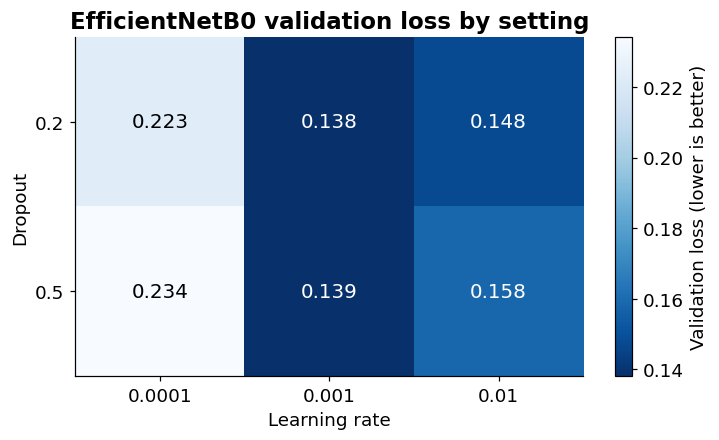

In [23]:
frozen_names = ["MobileNetV2 (frozen)", "EfficientNetB0 (frozen)", "ResNet50 (frozen)"]
TUNE_BACKBONE = max(frozen_names, key=lambda k: scores(y_val, val_probs[k])["F1"]).split(" (")[0]
TUNED, FINE = f"{TUNE_BACKBONE} tuned", f"{TUNE_BACKBONE} fine-tuned"
R["tune_backbone"] = TUNE_BACKBONE
print("Network chosen for tuning (best validation F1 when frozen):", TUNE_BACKBONE)

grid = []
best = None
for lr, dp in (list(itertools.product([1e-2, 1e-3, 1e-4], [0.2, 0.5]))[:2] if QUICK else itertools.product([1e-2, 1e-3, 1e-4], [0.2, 0.5])):
    tf.keras.utils.set_random_seed(SEED)
    m = build_transfer(TUNE_BACKBONE, augment=True, dropout=dp) #building a model with the selected settings
    h = fit(m, lr=lr)
    vl = float(min(h.history["val_loss"]))
    vs = scores(y_val, m.predict(val_ds, verbose=0).ravel())
    grid.append({"learning_rate": lr, "dropout": dp, "val_loss": round(vl, 4), **{k: round(v, 4) for k, v in vs.items()}})
    print(grid[-1])

    if best is None or vl < best[0]: #keeping the model with the lowest validation loss
        best = (vl, lr, dp, m, h)

grid = pd.DataFrame(grid)
display(grid)

_, best_lr, best_dp, tuned_model, tuned_hist = best
R["tuning_best"] = {"learning_rate": best_lr, "dropout": best_dp}
histories[TUNED] = tuned_hist #storing the tuned model's training history
models_by_name[TUNED] = tuned_model #storing the tuned model
print("Best setting:", R["tuning_best"], "| validation:", record(TUNED, tuned_model))

piv = grid.pivot(index="dropout", columns="learning_rate", values="val_loss")
fig, ax = plt.subplots(figsize=(7.5, 4))
im = ax.imshow(piv.values, cmap="Blues_r")
ax.set_xticks(range(piv.shape[1]), [f"{c:g}" for c in piv.columns])
ax.set_yticks(range(piv.shape[0]), [f"{i:g}" for i in piv.index])

for i, j in itertools.product(range(piv.shape[0]), range(piv.shape[1])):
    dark = piv.values[i, j] < piv.values.min() + 0.5 * (piv.values.max() - piv.values.min())
    ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", fontsize=13, color="white" if dark else "black")

ax.set(title=f"{TUNE_BACKBONE} validation loss by setting", xlabel="Learning rate", ylabel="Dropout")
plt.colorbar(im, ax=ax, label="Validation loss (lower is better)")
savefig("tuning_heatmap")

## 8. Fine-tuning
Starting from the tuned model, we unlock the last 30 layers of the pretrained network and keep training with a very small
learning rate (0.00001, the usual choice for fine-tuning), so the pretrained features can adapt to food without being overwritten.

C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Validation after fine-tuning: {'Accuracy': 0.9491525423728814, 'Precision': 0.9784172661870504, 'Recall': 0.918918918918919, 'F1': 0.9477351916376306, 'ROC-AUC': 0.9848777348777349} | gap: -0.065


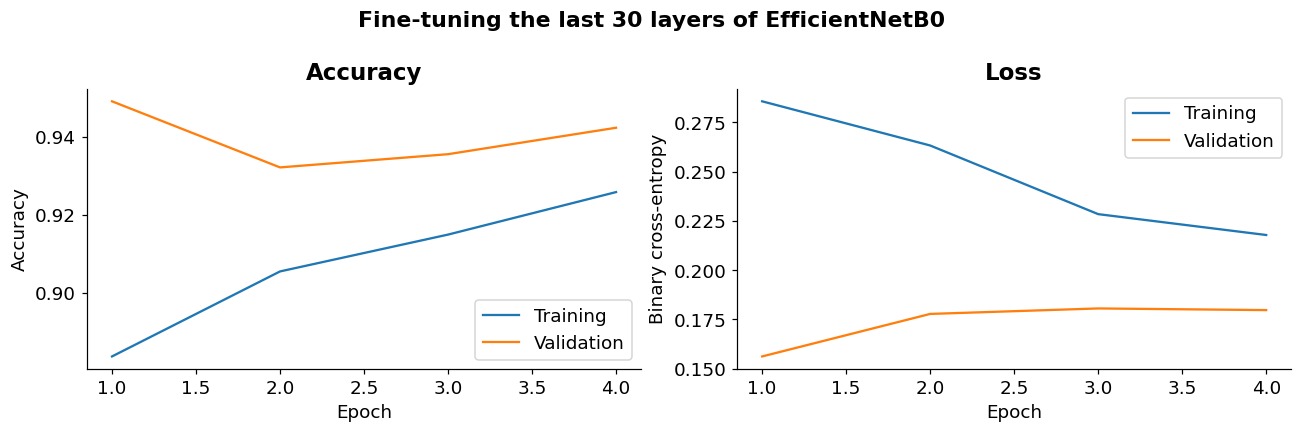

In [24]:
ft_model = build_transfer(TUNE_BACKBONE, augment=True, dropout=best_dp) #creating a separate copy of the tuned model
ft_model.set_weights(tuned_model.get_weights()) #copying the tuned weights

ft_base = INFO[id(ft_model)]["base"]
ft_base.trainable = True
for lyr in ft_base.layers[:-30]:
    lyr.trainable = False #freezing all but the last 30 layers

tf.keras.utils.set_random_seed(SEED)
histories[FINE] = h = fit(ft_model, lr=1e-5, epochs=10, patience=3) #fine-tuning with a lower learning rate
models_by_name[FINE] = ft_model

print("Validation after fine-tuning:", record(FINE, ft_model), "| gap:", round(gap(h), 3))
plot_history(h, f"Fine-tuning the last 30 layers of {TUNE_BACKBONE}", "curves_finetune")

## 9. Final evaluation on the held-out test set
The final model is the one with the best **validation** F1 (ROC-AUC breaks ties). Every model is then scored once
on the same test photos. A bootstrap gives a 95% confidence range for the final model's test accuracy.

In [25]:
ORDER = ["Majority guess (baseline)", "Small CNN (baseline)", "MobileNetV2, no augmentation", "MobileNetV2 (frozen)",
         "EfficientNetB0 (frozen)", "ResNet50 (frozen)", TUNED, FINE]

val_table = {k: scores(y_val, val_probs[k]) for k in ORDER}
candidates = [k for k in ORDER if "Majority" not in k]
final = max(candidates, key=lambda k: (round(val_table[k]["F1"], 4), val_table[k]["ROC-AUC"])) #selecting the best model using validation scores
test_table = {k: scores(y_test, test_probs[k]) for k in ORDER}
R.update(val_table=val_table, test_table=test_table, final_model=final)

p = test_probs[final]
yhat = (p >= 0.5).astype(int)
rng = np.random.RandomState(SEED)
boots = [(yhat[i] == y_test[i]).mean() for i in (rng.randint(0, len(p), len(p)) for _ in range(2000))] #estimating test accuracy uncertainty with bootstrap resampling
R["final_test_acc_95ci"] = [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))]

cm = confusion_matrix(y_test, yhat)
R["final_confusion"] = cm.tolist()
R["errors_fp"], R["errors_fn"] = int(cm[0, 1]), int(cm[1, 0]) #counting false positives and false negatives

print("Final model (chosen on validation F1):", final)
display(pd.concat({"validation": pd.DataFrame(val_table).T, "test": pd.DataFrame(test_table).T}, axis=1).round(3))
print("95% confidence range for test accuracy:", np.round(R["final_test_acc_95ci"], 3))

Final model (chosen on validation F1): EfficientNetB0 (frozen)


validation                                  \
                               Accuracy Precision Recall     F1 ROC-AUC   
Majority guess (baseline)         0.498     0.000  0.000  0.000   0.500   
Small CNN (baseline)              0.824     0.875  0.757  0.812   0.887   
MobileNetV2, no augmentation      0.936     0.939  0.932  0.936   0.984   
MobileNetV2 (frozen)              0.929     0.926  0.932  0.929   0.983   
EfficientNetB0 (frozen)           0.953     0.941  0.966  0.953   0.987   
ResNet50 (frozen)                 0.942     0.946  0.939  0.942   0.981   
EfficientNetB0 tuned              0.953     0.941  0.966  0.953   0.987   
EfficientNetB0 fine-tuned         0.949     0.978  0.919  0.948   0.985   

                                 test                                  
                             Accuracy Precision Recall     F1 ROC-AUC  
Majority guess (baseline)       0.502     0.000  0.000  0.000   0.500  
Small CNN (baseline)            0.776     0.840  0.680  0.752   0.880  
MobileNetV2, no augmentation    0.956     0.959  0.952  0.956   0.985  
MobileNetV2 (frozen)            0.942     0.933  0.952  0.943   0.988  
EfficientNetB0 (frozen)         0.959     0.966  0.952  0.959   0.993  
ResNet50 (frozen)               0.942     0.945  0.939  0.942   0.992  
EfficientNetB0 tuned            0.963     0.972  0.952  0.962   0.994  
EfficientNetB0 fine-tuned       0.953     0.978  0.925  0.951   0.993

95% confidence range for test accuracy: [0.936 0.98 ]


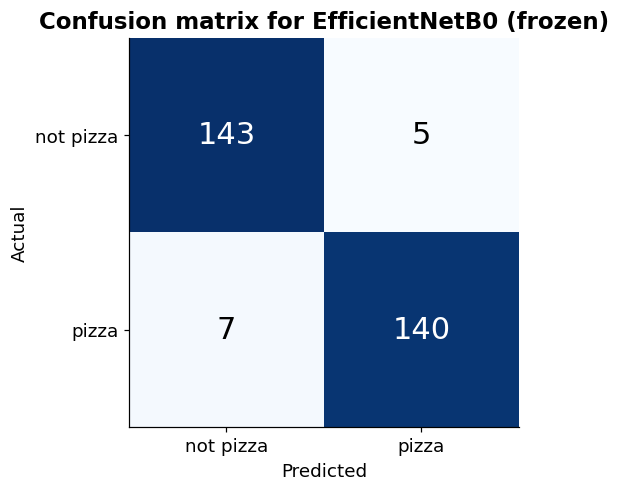

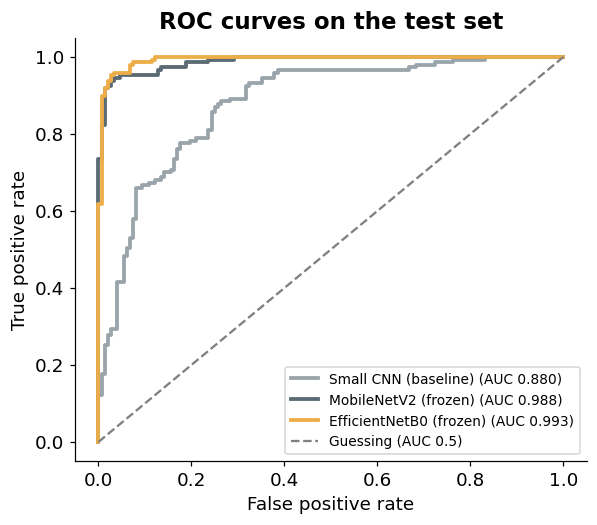

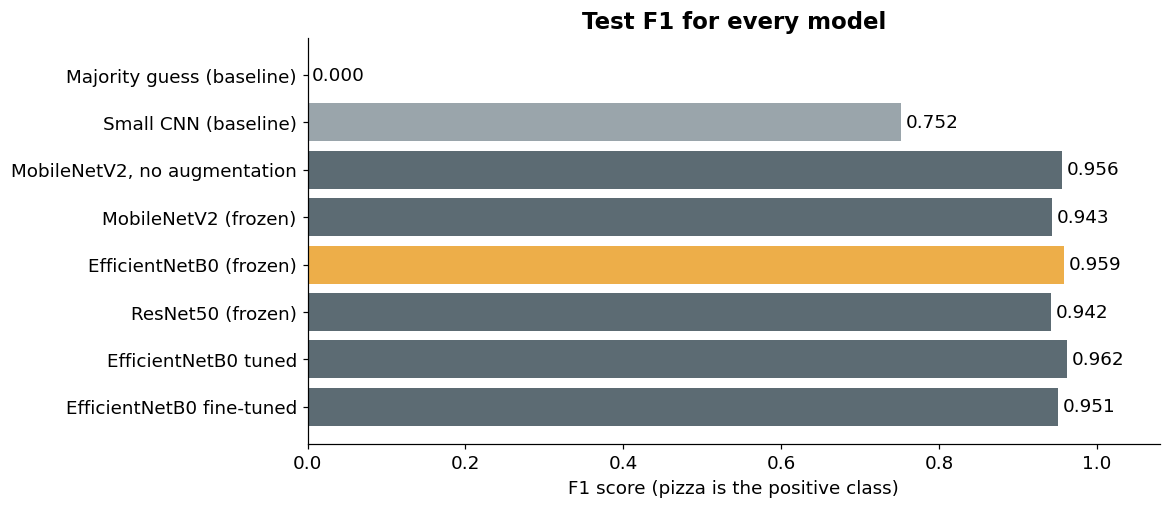

In [26]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.imshow(cm, cmap="Blues")
for i, j in itertools.product(range(2), range(2)):
    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=20,
            color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["not pizza", "pizza"])
ax.set_yticks([0, 1], ["not pizza", "pizza"])
ax.set(title=f"Confusion matrix for {final}", xlabel="Predicted", ylabel="Actual")
savefig("confusion_matrix")

fig, ax = plt.subplots(figsize=(6, 5))
for k, col in [("Small CNN (baseline)", COLORS["baseline"]), ("MobileNetV2 (frozen)", COLORS["neutral"]), (final, COLORS["highlight"])]:
    fpr, tpr, _ = roc_curve(y_test, test_probs[k]) #calculating false and true positive rates
    ax.plot(fpr, tpr, lw=2.5, color=col, label=f"{k} (AUC {test_table[k]['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Guessing (AUC 0.5)")
ax.set(title="ROC curves on the test set", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(fontsize=9, loc="lower right")
savefig("roc_curves")

fig, ax = plt.subplots(figsize=(10, 4.8))
vals = [test_table[k]["F1"] for k in ORDER]
cols = [COLORS["baseline"] if "baseline" in k else COLORS["highlight"] if k == final else COLORS["neutral"] for k in ORDER]
bars = ax.barh(ORDER[::-1], vals[::-1], color=cols[::-1])
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set(xlim=(0, 1.08), title="Test F1 for every model", xlabel="F1 score (pizza is the positive class)")
savefig("model_comparison")


## 10. Interpretation with Grad-CAM and a look at the mistakes
Grad-CAM makes a heat map of the parts of a photo that pushed the model toward saying pizza. We show it for
correct predictions and for the test photos the final model got wrong.

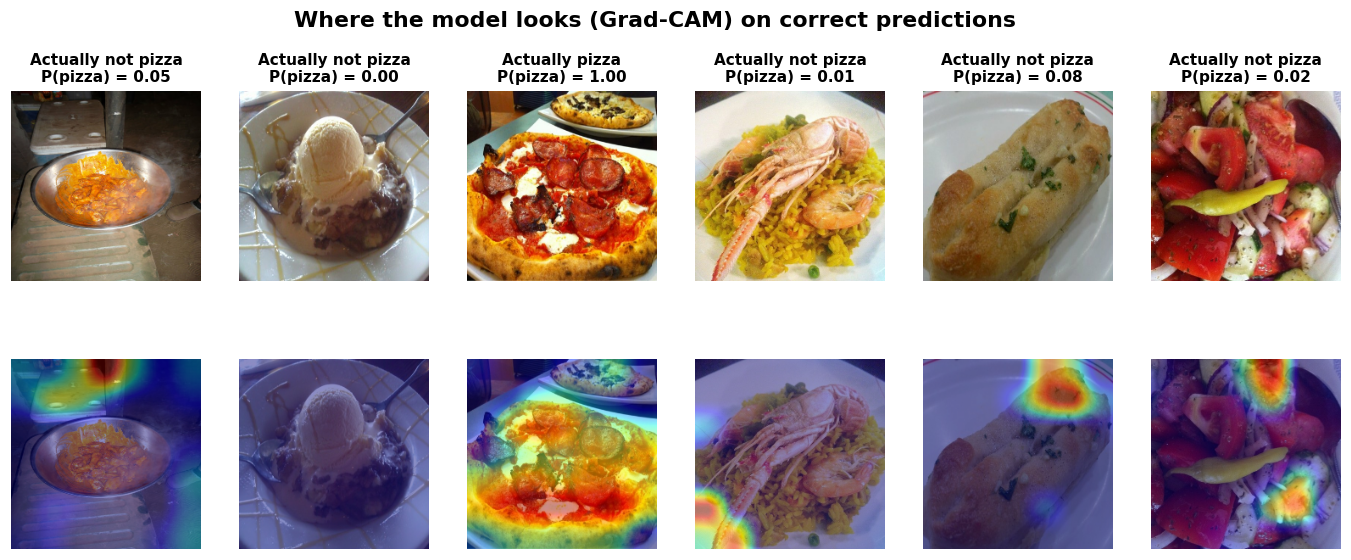

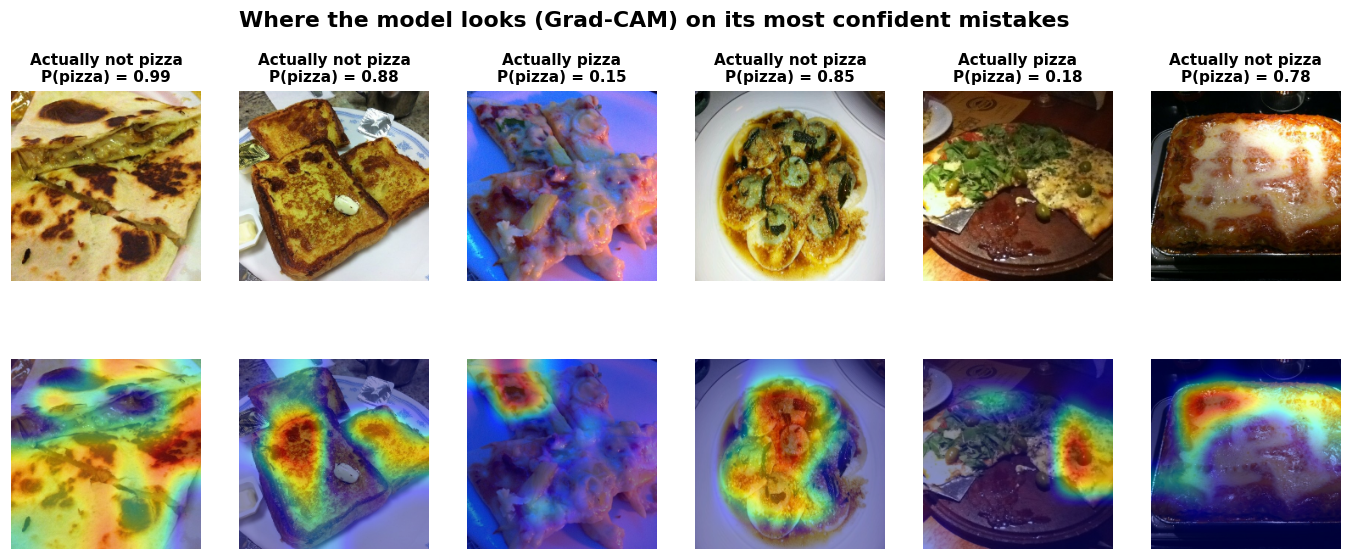

Test errors: 12 | false pizza: 5 | missed pizza: 7


In [27]:
cam_name = final if final in models_by_name and "Small CNN" not in final else FINE #using a pretrained model for Grad-CAM
final_model = models_by_name[cam_name]
R["gradcam_model"] = cam_name

test_imgs = np.concatenate([x.numpy() for x, _ in test_ds]) #collecting test images
pf = test_probs[cam_name]
wrong = np.where((pf >= 0.5) != y_test)[0]
right = np.where((pf >= 0.5) == y_test)[0]
R["n_test_errors"] = int(len(wrong))
R["error_files"] = [Path(test_paths[i]).name for i in wrong]

gradcam_grid(
    np.random.RandomState(SEED).choice(right, 6, replace=False),
    "Where the model looks (Grad-CAM) on correct predictions",
    "gradcam_correct"
)

if len(wrong):
    gradcam_grid(
        wrong[np.argsort(-np.abs(pf[wrong] - 0.5))][:6],
        "Where the model looks (Grad-CAM) on its most confident mistakes",
        "gradcam_errors"
    )

print("Test errors:", R["n_test_errors"], "| false pizza:", R["errors_fp"], "| missed pizza:", R["errors_fn"])

## 11. Saving Results and Experiment Metadata

Results from the modeling workflow are consolidated into a single JSON file for reproducibility and reference. The saved information includes training history summaries, hyperparameter tuning results, and dataset split sizes, along with the other metrics and evaluation details recorded throughout the notebook.

The output is saved to `outputs/tf/results.json`, allowing the results of the experiments to be reviewed without rerunning every model.

In [28]:
R["histories"] = {
    k: {
        "epochs": len(h.history["loss"]),
        "gap": round(gap(h), 4),
        "best_val_loss": round(float(min(h.history["val_loss"])), 4),
        "seconds": None if np.isnan(h.history.get("seconds", np.nan)) else round(h.history["seconds"], 1)
    }
    for k, h in histories.items()
} #storing training history summaries for each model

R["tuning_grid"] = grid.to_dict("records") #saving the hyperparameter tuning results
R["small_cnn_val_acc_end"] = float(histories["Small CNN (baseline)"].history["val_accuracy"][-1])
R["split"] = {"train": len(train_paths), "val": len(val_paths), "test": len(test_paths)} #recording dataset split sizes

with open(OUT / "results.json", "w") as f:
    json.dump(R, f, indent=1, default=float) #saving all recorded results to JSON

print("saved", OUT / "results.json")

saved outputs\tf\results.json
